# 02 — Synthetic Outage V2: Weather Coverage and Event Context

**Analytical report · Bataan, Philippines · Updated 26 October 2026**

## 1. Scope and dataset summary

The main event source is **Synthetic Outage V2**, verified against its generation manifest. The report assesses source coverage and temporal alignment, then describes municipal weather and ERA5 atmospheric conditions around one selected V2 event.

- **V2 population:** 10,608 simulated unplanned events across 237 origin barangays and 12 municipalities. The generation interval is 2019-01-01 08:00:00+08:00 through 2026-06-30 23:00:00+08:00.
- **Selected case:** `SYN-V2-42-0009590` in Santa Rosa, Pilar; onset 2025-07-06 08:00:00+08:00, duration 263.26 minutes. The deterministic selection rule is the earliest July 2025 Weather / Storm event lasting at least one hour, allowing several hourly samples during the event. This is an illustrative case, not a representative outage sample.
- **Analysis window:** 24 hours before onset, the exact outage interval, and 12 hours after restoration. An additional 24 hours of history supports trailing calculations.
- **Pre-event snapshot:** prediction cutoff one hour before onset; latest observation label another hour earlier. This matches the V2 next-hour target convention and separates advance inputs from retrospective context.

All occurrences, causes, durations and origin-barangay assignments are simulated. Municipality allocation is only partially calibrated to resolvable PENELCO records; the report does not establish real outage causes or forecasting accuracy. No model is trained and no source dataset is changed.

## 2. Sources and provenance

| Source | Analytical role |
|---|---|
| `data/synthetic/v2_20261024T181237_896469Z/synthetic_outage_events_v2.csv` | Main V2 event population and selected origin-barangay event |
| The same run's `run_manifest.json` | Version, source checksums and declared simulation coverage |
| `data/boundaries/bataan_barangays.geojson` | Authoritative PSGC relationships and location labels |
| `data/weather/open_meteo_bataan_2019_01_to_2026_06.csv` | Municipal hourly precipitation, wind, gust, temperature, humidity, pressure and soil moisture |
| `data/weather/era5_bataan_2019_01_to_2026_06.nc` | Atmospheric context at the selected event's recorded 0.25° grid cell |
| `notebooks/assessment/weather_feature_contract.json` | Diagnostic window definitions and assumed observation lag; not a validated forecasting contract |

The V1 event CSV is not loaded. Original weather export headers document the units. Naive Open-Meteo clocks are localized to Asia/Singapore (UTC+8), then converted to Asia/Manila; ERA5 times are decoded in UTC before conversion. Historical publication times and forecast-vintage metadata are unavailable.

In [1]:
from pathlib import Path
from zoneinfo import ZoneInfo
import hashlib
import json
import math

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Markdown, display

MANILA = ZoneInfo("Asia/Manila")
BLUE, GOLD, GREY = "#28618C", "#B67820", "#555555"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
root_candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in root_candidates
    if (path / "scripts/generate_synthetic_outages.py").is_file()
    and (path / "data/synthetic").is_dir()), None)
assert project_root is not None, "Run from this repository or its notebooks directory."
v2_run = project_root / "data/synthetic/v2_20261024T181237_896469Z"
sources = {
    "events": v2_run / "synthetic_outage_events_v2.csv",
    "event_manifest": v2_run / "run_manifest.json",
    "boundaries": project_root / "data/boundaries/bataan_barangays.geojson",
    "weather": project_root / "data/weather/open_meteo_bataan_2019_01_to_2026_06.csv",
    "era5": project_root / "data/weather/era5_bataan_2019_01_to_2026_06.nc",
    "contract": project_root / "notebooks/assessment/weather_feature_contract.json",
}
assert all(path.is_file() for path in sources.values())
def fingerprint(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
source_hashes_before = {name: fingerprint(path) for name, path in sources.items()}
v2_manifest = json.loads(sources["event_manifest"].read_text(encoding="utf-8"))
assert v2_manifest["is_synthetic"] and v2_manifest["generator_version"].startswith("2.")
assert source_hashes_before["events"] == v2_manifest["event_csv"]["sha256"]
for name, manifest_name in [("boundaries", "geography"), ("weather", "weather"), ("era5", "era5")]:
    assert source_hashes_before[name] == v2_manifest["inputs"][manifest_name]["sha256"]
contract = json.loads(sources["contract"].read_text(encoding="utf-8"))
assert contract["alignment"]["historical_reconstruction_lag_hours"] == 1
display(pd.DataFrame([{"Source": name, "File": str(path.relative_to(project_root)),
    "SHA-256 prefix": source_hashes_before[name][:16]} for name, path in sources.items()]))

,Source,File,SHA-256 prefix
0,events,data\synthetic\v2_20261024T181237_896469Z\synt...,aac4e9bade4f765d
1,event_manifest,data\synthetic\v2_20261024T181237_896469Z\run_...,5139f42a28c88645
2,boundaries,data\boundaries\bataan_barangays.geojson,6bcaa724a5257eb8
3,weather,data\weather\open_meteo_bataan_2019_01_to_2026...,4b2329a0a59529ad
4,era5,data\weather\era5_bataan_2019_01_to_2026_06.nc,c95e43f8711a8ddf
5,contract,notebooks\assessment\weather_feature_contract....,dcb84f42fea3d4df


## 3. V2 population and case selection

The selected case is the earliest July 2025 Weather / Storm event with a duration of at least 60 minutes. This duration criterion provides sufficient hourly temporal support without selecting a case based on its weather values. The generated cause is an event attribute, not evidence of a meteorological failure mechanism.

The annual overview retains the partial 2026 interval explicitly. Exposure-normalized frequencies use the declared V2 generation hours and the origin-barangay universe; they describe simulation allocation, not observed PENELCO reliability or the active-masked ML population.

In [3]:
selected_outage_id = None  # Optional explicit V2 ID; default follows the documented selection rule.
events = pd.read_csv(sources["events"], dtype={
    "outage_id": "string", "barangay_psgc": "string", "municipality_psgc": "string"})
assert events.outage_id.is_unique and events.is_synthetic.eq(True).all()
assert events.generator_version.astype(str).str.startswith("2.").all()
all_onsets = pd.to_datetime(events.start_time, format="mixed", utc=True).dt.tz_convert(MANILA)
all_restorations = pd.to_datetime(events.end_time, format="mixed", utc=True).dt.tz_convert(MANILA)
assert (all_restorations > all_onsets).all()
assert not events.cause_category.str.contains("scheduled|planned", case=False).any()
if selected_outage_id is None:
    candidates = events.loc[events.cause_category.eq("Weather / Storm")
        & events.duration_minutes.ge(60)
        & all_onsets.ge(pd.Timestamp("2025-07-01", tz=MANILA))
        & all_onsets.lt(pd.Timestamp("2025-08-01", tz=MANILA))]
    assert not candidates.empty
    selected_outage_id = candidates.sort_values(["start_time", "outage_id"]).iloc[0].outage_id
matches = events.loc[events.outage_id.eq(selected_outage_id)]
assert len(matches) == 1, "The selected ID must identify exactly one V2 event."
event = matches.iloc[0]
onset = pd.to_datetime(event.start_time, format="mixed", utc=True).tz_convert(MANILA)
restoration = pd.to_datetime(event.end_time, format="mixed", utc=True).tz_convert(MANILA)
assert onset == onset.floor("h"), "V2 case analysis requires an hourly-aligned onset."
assert restoration > onset
assert np.isclose((restoration - onset).total_seconds() / 60, event.duration_minutes)
display(pd.Series({"V2 event": event.outage_id, "cause (synthetic)": event.cause_category,
    "barangay": event.barangay, "municipality": event.municipality,
    "onset (Manila)": str(onset), "restoration (Manila)": str(restoration),
    "duration (minutes)": event.duration_minutes}, name="Selected V2 case"))
generation_start = pd.Timestamp(v2_manifest["period"]["start_local"])
generation_end = pd.Timestamp(v2_manifest["period"]["end_local"])
generation_hours = pd.date_range(generation_start, generation_end, freq="h", inclusive="left")
annual_overview = events.groupby(all_onsets.dt.year).size().rename("Events").to_frame()
annual_overview["Generation hours / barangay"] = pd.Series(generation_hours.year).value_counts().sort_index()
annual_overview["Events / 10,000 barangay-hours"] = (10000 * annual_overview.Events
    / (annual_overview["Generation hours / barangay"] * events.barangay_psgc.nunique()))
display(annual_overview.round(3))
display(Markdown(f"**Population:** {len(events):,} V2 events, {events.barangay_psgc.nunique()} origin barangays, "
    f"{events.municipality_psgc.nunique()} municipalities; event starts range from {all_onsets.min()} to {all_onsets.max()}. "
    "2026 is January–June only; its total is interpreted alongside its exposure denominator."))

V2 event                               SYN-V2-42-0009590
cause (synthetic)                        Weather / Storm
barangay                                      Santa Rosa
municipality                                       Pilar
onset (Manila)                 2025-07-06 08:00:00+08:00
restoration (Manila)    2025-07-06 12:23:15.600000+08:00
duration (minutes)                                263.26
Name: Selected V2 case, dtype: object

,Events,Generation hours / barangay,"Events / 10,000 barangay-hours"
start_time,,,
2019,1432,8752,6.904
2020,1473,8784,7.076
2021,1539,8760,7.413
2022,1402,8760,6.753
2023,1505,8760,7.249
2024,1324,8784,6.360
2025,1380,8760,6.647
2026,553,4343,5.373


**Population:** 10,608 V2 events, 237 origin barangays, 12 municipalities; event starts range from 2019-01-01 08:00:00+08:00 to 2026-06-30 06:00:00+08:00. 2026 is January–June only; its total is interpreted alongside its exposure denominator.

### Geographic alignment

Origin PSGCs and municipality relationships are checked against the boundary source. The selected municipality is matched to its historical weather name through the Balanga alias. Municipal weather is shared environmental context; it is not an observation at the fault location or evidence about electrically affected barangays.

In [4]:
boundary_json = json.loads(sources["boundaries"].read_text(encoding="utf-8"))
boundary_rows = pd.DataFrame([feature["properties"] for feature in boundary_json["features"]])
assert boundary_rows.barangay_psgc.is_unique
assert events.barangay_psgc.isin(boundary_rows.barangay_psgc).all()
parent_lookup = boundary_rows.set_index("barangay_psgc").municipality_psgc
assert events.municipality_psgc.eq(events.barangay_psgc.map(parent_lookup)).all()
boundary_match = boundary_rows.loc[boundary_rows.barangay_psgc.eq(event.barangay_psgc)]
assert len(boundary_match) == 1
boundary = boundary_match.iloc[0]
for field in ["barangay", "municipality_psgc", "municipality"]:
    assert event[field] == boundary[field], f"Boundary mismatch: {field}"
weather_name_aliases = {"City of Balanga": "Balanga"}
weather_municipality = weather_name_aliases.get(event.municipality, event.municipality)
location_id = "municipality:" + event.municipality_psgc
print(f"{event.municipality} ({event.municipality_psgc}) → weather name: {weather_municipality}")

Pilar (0300811000) → weather name: Pilar


## 4. Weather coverage and temporal alignment

The case timeline spans onset minus 24 hours through restoration plus 12 hours. Additional earlier history initializes trailing aggregates. Exact restoration timestamps are retained.

Rainfall is an amount over a preceding hourly interval. The next full record is retained as support for the final overlapping interval without prorating its value. Instantaneous samples beyond the exact visible endpoint remain outside the displayed timeline.

In [5]:
timeline_start = onset - pd.Timedelta(hours=24)
timeline_end = restoration + pd.Timedelta(hours=12)
read_start = timeline_start - pd.Timedelta(hours=24)
read_end = timeline_end.ceil("h")
expected_hours = pd.date_range(read_start, read_end, freq="h")
display(pd.Series({"visible start": str(timeline_start), "visible end": str(timeline_end),
    "loaded start (extra history)": str(read_start), "loaded end (hour support)": str(read_end)}, name="Manila times"))

visible start                          2025-07-05 08:00:00+08:00
visible end                     2025-07-07 00:23:15.600000+08:00
loaded start (extra history)           2025-07-04 08:00:00+08:00
loaded end (hour support)              2025-07-07 01:00:00+08:00
Name: Manila times, dtype: str

### Municipal source coverage

The weather source is scanned in chunks. Coverage, duplicate keys, timestamp gaps, missing values and coordinate reuse are summarized for every municipality. Only the selected case window is retained for detailed time-series analysis. Source clocks retain their recorded UTC+8 interpretation throughout.

In [6]:
weather_columns = ["municipality", "latitude", "longitude", "elevation_m",
    "timezone", "utc_offset_seconds", "time", "precipitation_mm",
    "wind_speed_10m_m_s", "wind_gusts_10m_m_s", "temperature_2m_c",
    "relative_humidity_2m_pct", "surface_pressure_hpa",
    "soil_moisture_0_to_7cm_m3_m3", "soil_moisture_7_to_28cm_m3_m3"]
weather_parts, location_parts, coverage_parts = [], [], []
coverage_missing = None
gust_below_speed_source_hours = 0
source_value_columns = ["precipitation_mm", "wind_speed_10m_m_s", "wind_gusts_10m_m_s",
    "temperature_2m_c", "relative_humidity_2m_pct", "surface_pressure_hpa",
    "soil_moisture_0_to_7cm_m3_m3", "soil_moisture_7_to_28cm_m3_m3"]
for chunk in pd.read_csv(sources["weather"], usecols=weather_columns, chunksize=100_000):
    assert chunk.timezone.eq("Asia/Singapore").all() and chunk.utc_offset_seconds.eq(28800).all()
    coverage_parts.append(chunk[["municipality", "time", "latitude", "longitude"]].copy())
    nulls = chunk[source_value_columns].isna().groupby(chunk.municipality).sum()
    coverage_missing = nulls if coverage_missing is None else coverage_missing.add(nulls, fill_value=0)
    gust_below_speed_source_hours += int(chunk.wind_gusts_10m_m_s.lt(chunk.wind_speed_10m_m_s).sum())
    local_rows = chunk.loc[chunk.municipality.eq(weather_municipality)].copy()
    if local_rows.empty:
        continue
    assert local_rows.timezone.eq("Asia/Singapore").all()
    assert local_rows.utc_offset_seconds.eq(28800).all()
    location_parts.append(local_rows[["municipality", "latitude", "longitude", "elevation_m"]].drop_duplicates())
    local_rows["timestamp"] = pd.to_datetime(local_rows.time, errors="raise").dt.tz_localize(
        "Asia/Singapore").dt.tz_convert(MANILA)
    weather_parts.append(local_rows.loc[local_rows.timestamp.between(read_start, read_end)])
assert weather_parts, "No matching weather municipality found."
weather_slice = pd.concat(weather_parts, ignore_index=True).sort_values("timestamp")
location_metadata = pd.concat(location_parts, ignore_index=True).drop_duplicates()
assert len(location_metadata) == 1, "Review changing or ambiguous weather coordinates."
display(location_metadata.reset_index(drop=True))
weather_keys = pd.concat(coverage_parts, ignore_index=True)
weather_keys["valid_time"] = pd.to_datetime(weather_keys.time).dt.tz_localize("Asia/Singapore").dt.tz_convert(MANILA)
assert not weather_keys.duplicated(["municipality", "valid_time"]).any()
coverage_rows = []
for municipality, group in weather_keys.groupby("municipality", sort=True):
    index = pd.DatetimeIndex(group.valid_time).sort_values()
    expected = pd.date_range(index.min(), index.max(), freq="h")
    coordinates = group[["latitude", "longitude"]].drop_duplicates()
    assert len(coordinates) == 1
    coverage_rows.append({"Municipality": municipality, "First local hour": str(index.min()),
        "Last local hour": str(index.max()), "Hourly records": len(index),
        "Missing hours": len(expected.difference(index)),
        "Missing weather cells": int(coverage_missing.loc[municipality].sum())})
coverage_table = pd.DataFrame(coverage_rows)
expected_names = set(boundary_rows.municipality.replace({"City of Balanga": "Balanga"}))
assert set(weather_keys.municipality) == expected_names
assert coverage_table["Missing hours"].eq(0).all()
assert coverage_table["Missing weather cells"].eq(0).all()
unique_weather_coordinates = len(weather_keys[["latitude", "longitude"]].drop_duplicates())
display(coverage_table)
display(Markdown(f"**Source coverage:** {len(weather_keys):,} municipality-hour records with no duplicate keys, "
    f"timestamp gaps or missing weather values. The {len(coverage_table)} municipal series use only "
    f"{unique_weather_coordinates} distinct coordinate pairs; repeated locations are not independent stations. "
    f"{gust_below_speed_source_hours:,} source hours have supplied gust below wind speed. These values are "
    "retained as an unresolved measurement/model/interval consistency issue; no correction is fabricated."))

,municipality,latitude,longitude,elevation_m
0,Pilar,14.657293,120.52974,4.0


,Municipality,First local hour,Last local hour,Hourly records,Missing hours,Missing weather cells
0,Abucay,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
1,Bagac,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
2,Balanga,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
3,Dinalupihan,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
4,Hermosa,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
5,Limay,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
6,Mariveles,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
7,Morong,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
8,Orani,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0
9,Orion,2019-01-01 00:00:00+08:00,2026-06-30 23:00:00+08:00,65712,0,0


**Source coverage:** 788,544 municipality-hour records with no duplicate keys, timestamp gaps or missing weather values. The 12 municipal series use only 7 distinct coordinate pairs; repeated locations are not independent stations. 938 source hours have supplied gust below wind speed. These values are retained as an unresolved measurement/model/interval consistency issue; no correction is fabricated.

### Selected-window integrity

The case slice is checked for a unique municipality-hour key, complete hourly support, finite values and physical ranges. Missing observations remain unknown rather than becoming zero rainfall. The displayed checks describe this event window; full-source coverage is reported separately above.

In [7]:
weather_values = ["precipitation_mm", "wind_speed_10m_m_s", "wind_gusts_10m_m_s",
    "temperature_2m_c", "relative_humidity_2m_pct", "surface_pressure_hpa",
    "soil_moisture_0_to_7cm_m3_m3", "soil_moisture_7_to_28cm_m3_m3"]
assert weather_slice.municipality.eq(weather_municipality).all()
assert not weather_slice.timestamp.duplicated().any(), "Duplicate municipality/hour keys."
assert weather_slice.timestamp.eq(weather_slice.timestamp.dt.floor("h")).all()
assert np.isfinite(weather_slice[weather_values].to_numpy(dtype=float)).all()
assert weather_slice[["precipitation_mm", "wind_speed_10m_m_s", "wind_gusts_10m_m_s"]].ge(0).all().all()
assert weather_slice.relative_humidity_2m_pct.between(0, 100).all()
assert weather_slice.surface_pressure_hpa.gt(0).all()
soil_columns = ["soil_moisture_0_to_7cm_m3_m3", "soil_moisture_7_to_28cm_m3_m3"]
assert weather_slice[soil_columns].ge(0).all().all() and weather_slice[soil_columns].le(1).all().all()
missing_hours = expected_hours.difference(pd.DatetimeIndex(weather_slice.timestamp))
weather_hourly = weather_slice.set_index("timestamp")[weather_values].reindex(expected_hours)
weather_hourly.index.name = "valid_time"
weather_hourly["location_id"] = location_id
display(pd.Series({"expected hourly records": len(expected_hours), "observed records": len(weather_slice),
    "missing timestamps": len(missing_hours), "null weather cells": int(weather_hourly[weather_values].isna().sum().sum())}, name="Window checks"))
assert len(missing_hours) == 0, "Incomplete event window; investigate rather than zero-fill."
assert weather_hourly[weather_values].notna().all().all()

expected hourly records    66
observed records           66
missing timestamps          0
null weather cells          0
Name: Window checks, dtype: int64

In [8]:
visible_labels = weather_hourly.loc[timeline_start:timeline_end]
hour_support = weather_hourly.loc[timeline_start:read_end]
print(f"Visible hourly labels: {len(visible_labels)}; rainfall support labels: {len(hour_support)}")
preview = visible_labels[["precipitation_mm", "wind_speed_10m_m_s", "wind_gusts_10m_m_s"]].copy()
preview.index = preview.index.strftime("%d %b %H:%M")
preview.columns = ["Rain (mm)", "Wind (m/s)", "Supplied gust (m/s)"]
display(pd.concat([preview.head(3), preview.tail(3)]))

Visible hourly labels: 41; rainfall support labels: 42


,Rain (mm),Wind (m/s),Supplied gust (m/s)
valid_time,,,
05 Jul 08:00,1.5,2.47,6.8
05 Jul 09:00,0.9,2.05,6.8
05 Jul 10:00,3.9,2.37,6.5
06 Jul 22:00,0.1,0.90,3.9
06 Jul 23:00,0.1,0.81,2.8
07 Jul 00:00,0.2,1.35,3.7


## 5. Antecedent weather conditions

Precipitation at observation label `s` covers `(s−1 hour, s]`. Wind speed is a supplied hourly scalar sample. Gust semantics depend on the original provider/model; **maximum supplied gust** therefore denotes the maximum among recorded hourly values rather than a verified continuous-time gust maximum.

| Diagnostic aggregate ending at observation cutoff `c` | Hourly labels | Units |
|---|---|---|
| 6-hour precipitation | `c−5h … c`, summed | mm |
| 24-hour precipitation | `c−23h … c`, summed | mm |
| 6-hour mean wind speed | `c−5h … c`, averaged | m/s |
| 6-hour maximum supplied gust | `c−5h … c`, maximum | m/s |

Every aggregate requires all expected observations. These are descriptive case-study diagnostics; they do not replace the V2 predictor whitelist. Provider semantics are documented in the [historical weather documentation](https://open-meteo.com/en/docs/historical-weather-api).

### Prediction cutoff and observation cutoff

The case's V2 prediction cutoff is `t = onset − 1 hour`, so its target window `(t, t+1 hour]` contains this exact-hour onset. The assumed observation lag is one additional hour: the latest usable observation label is `c = t − 1 hour = onset − 2 hours`.

This ordering prevents the target-hour weather from entering the pre-event snapshot. It does not prove historical publication availability; reanalysis release times and forecast vintages remain unavailable.

In [9]:
issue_time = onset - pd.Timedelta(hours=1)
assumed_lag = pd.Timedelta(hours=contract["alignment"]["historical_reconstruction_lag_hours"])
cutoff = issue_time - assumed_lag
six_labels = pd.date_range(cutoff - pd.Timedelta(hours=5), cutoff, freq="h")
twenty_four_labels = pd.date_range(cutoff - pd.Timedelta(hours=23), cutoff, freq="h")
six_hour_values = weather_hourly.reindex(six_labels)[weather_values]
twenty_four_rain = weather_hourly.reindex(twenty_four_labels).precipitation_mm
assert six_hour_values.notna().all().all() and twenty_four_rain.notna().all()
print("Prediction cutoff:", issue_time, "| last observation label:", cutoff)
assert issue_time < onset <= issue_time + pd.Timedelta(hours=1)
print("6h precipitation interval:", cutoff - pd.Timedelta(hours=6), "to", cutoff)
print("24h precipitation interval:", cutoff - pd.Timedelta(hours=24), "to", cutoff)

Prediction cutoff: 2025-07-06 07:00:00+08:00 | last observation label: 2025-07-06 06:00:00+08:00
6h precipitation interval: 2025-07-06 00:00:00+08:00 to 2025-07-06 06:00:00+08:00
24h precipitation interval: 2025-07-05 06:00:00+08:00 to 2025-07-06 06:00:00+08:00


### Location-specific trailing aggregates

Rolling calculations stay within a weather location and use only complete trailing histories. Observation cutoff labels are shifted by the fixed one-hour lag to the corresponding prediction cutoff. Leading incomplete windows remain null. The snapshot below is evaluated one hour before the selected onset.

In [10]:
feature_parts = []
for group_location, local_weather in weather_hourly.groupby("location_id", sort=False):
    local_weather = local_weather.sort_index()
    rainfall = local_weather.precipitation_mm
    wind = local_weather.wind_speed_10m_m_s
    supplied_gust = local_weather.wind_gusts_10m_m_s
    local_features = pd.DataFrame({
        "rain_sum_6h_mm": rainfall.rolling("6h", closed="right", min_periods=6).sum(),
        "rain_sum_24h_mm": rainfall.rolling("24h", closed="right", min_periods=24).sum(),
        "wind_mean_6h_m_s": wind.rolling("6h", closed="right", min_periods=6).mean(),
        "gust_max_6h_m_s": supplied_gust.rolling("6h", closed="right", min_periods=6).max(),
    })
    local_features["location_id"] = group_location
    local_features.index = local_features.index + assumed_lag
    feature_parts.append(local_features)
weather_features = pd.concat(feature_parts).rename_axis("issue_time")
pre_event_features = weather_features.loc[issue_time].drop("location_id").astype(float)
display(pre_event_features.to_frame("Value one hour before onset (additional 1h observation lag)").round(4))

,Value one hour before onset (additional 1h observation lag)
rain_sum_6h_mm,1.7000
rain_sum_24h_mm,28.7000
wind_mean_6h_m_s,1.7017
gust_max_6h_m_s,5.4000


## 6. Numerical consistency

Independent summation, arithmetic means and maxima are compared with the rolling implementation over the actual source observations. Agreement checks the calculations without fitting a model or asserting that the diagnostics predict outages.

In [11]:
independent_values = pd.Series({
    "rain_sum_6h_mm": math.fsum(six_hour_values.precipitation_mm.tolist()),
    "rain_sum_24h_mm": math.fsum(twenty_four_rain.tolist()),
    "wind_mean_6h_m_s": math.fsum(six_hour_values.wind_speed_10m_m_s.tolist()) / 6,
    "gust_max_6h_m_s": max(six_hour_values.wind_gusts_10m_m_s.tolist()),
})
feature_comparison = pd.DataFrame({"Rolling calculation": pre_event_features,
    "Independent calculation": independent_values})
feature_comparison["Absolute difference"] = (feature_comparison.iloc[:, 0] - feature_comparison.iloc[:, 1]).abs()
assert np.allclose(pre_event_features, independent_values, rtol=0, atol=1e-10)
display(feature_comparison.round(6))

,Rolling calculation,Independent calculation,Absolute difference
rain_sum_6h_mm,1.700000,1.700000,0.0
rain_sum_24h_mm,28.700000,28.700000,0.0
wind_mean_6h_m_s,1.701667,1.701667,0.0
gust_max_6h_m_s,5.400000,5.400000,0.0


In [12]:
display(Markdown(f"**Pre-event snapshot at {issue_time:%d %b %Y %H:%M} Manila:** "
    f"the latest observation label is {cutoff:%d %b %H:%M}. Precipitation totals are "
    f"{pre_event_features.rain_sum_6h_mm:.2f} mm over 6 hours and {pre_event_features.rain_sum_24h_mm:.2f} mm over 24 hours. "
    f"Mean wind is {pre_event_features.wind_mean_6h_m_s:.2f} m/s and maximum supplied gust is "
    f"{pre_event_features.gust_max_6h_m_s:.2f} m/s over 6 hours. "
    "These values characterize antecedent municipal conditions and do not establish an outage cause."))

**Pre-event snapshot at 06 Jul 2025 07:00 Manila:** the latest observation label is 06 Jul 06:00. Precipitation totals are 1.70 mm over 6 hours and 28.70 mm over 24 hours. Mean wind is 1.70 m/s and maximum supplied gust is 5.40 m/s over 6 hours. These values characterize antecedent municipal conditions and do not establish an outage cause.

## 7. Event weather and atmospheric context

Gold shading marks the exact V2 outage interval; dashed lines mark onset and dotted lines mark restoration. Precipitation bars occupy their recorded preceding hour without prorating edge amounts. Rolling curves use prediction-cutoff labels with the additional one-hour observation lag.

The figures include before, during and after conditions for retrospective interpretation. Any value later than the pre-event observation cutoff is excluded from that pre-event snapshot.

In [13]:
tick_times = list(pd.date_range(timeline_start, timeline_end, freq="6h"))
if (timeline_end - tick_times[-1]) < pd.Timedelta(hours=3):
    tick_times.pop()  # Keep the exact right endpoint readable.
tick_times.append(timeline_end)
def mark_outage(axis):
    axis.axvspan(onset, restoration, color=GOLD, alpha=0.2, label="Synthetic outage")
    axis.axvline(onset, color=GREY, linestyle="--", linewidth=1)
    axis.axvline(restoration, color=GREY, linestyle=":", linewidth=1)
    axis.set_xlim(timeline_start, timeline_end)
    axis.set_xticks(tick_times)
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M", tz=MANILA))
    axis.grid(axis="y", alpha=0.15)
    axis.set_ylim(bottom=0)

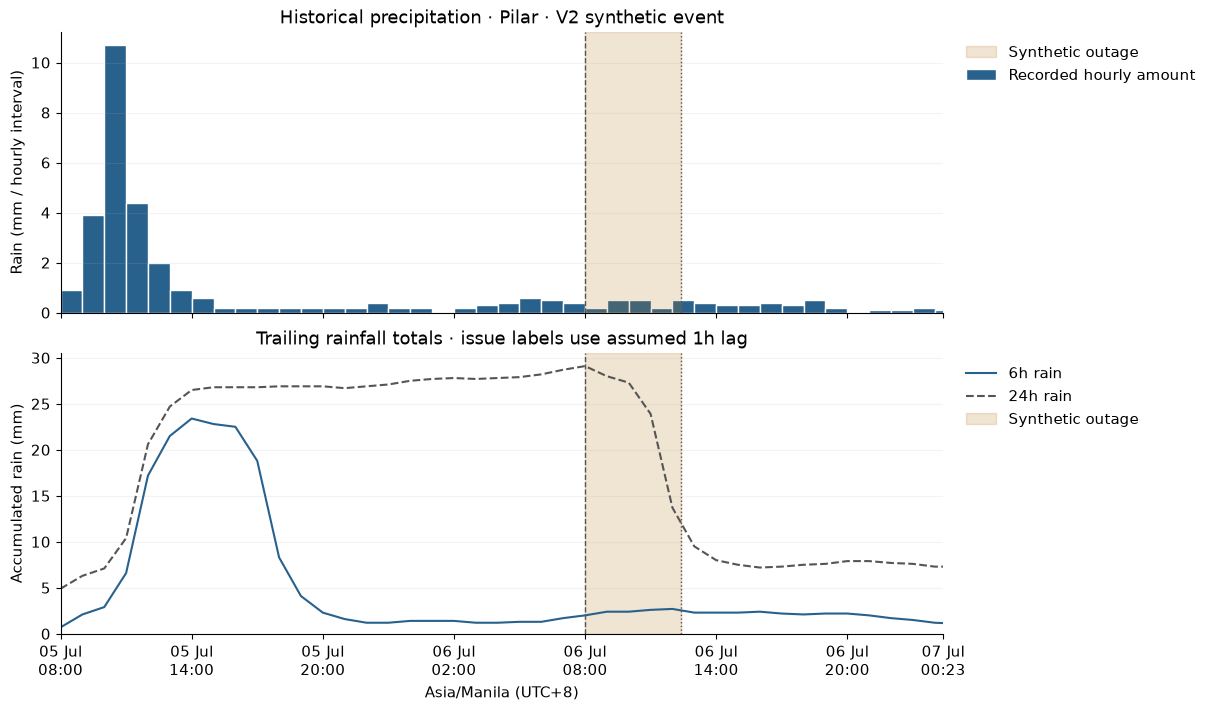

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
rain_left_edges = hour_support.index - pd.Timedelta(hours=1)
axes[0].bar(rain_left_edges, hour_support.precipitation_mm, width=1/24,
            align="edge", color=BLUE, edgecolor="white", label="Recorded hourly amount")
axes[0].set(title=f"Historical precipitation · {weather_municipality} · V2 synthetic event", ylabel="Rain (mm / hourly interval)")
for feature, label, style, color in [("rain_sum_6h_mm", "6h rain", "-", BLUE), ("rain_sum_24h_mm", "24h rain", "--", GREY)]:
    axes[1].plot(weather_features.index, weather_features[feature], linestyle=style, color=color, label=label)
axes[1].set(title="Trailing rainfall totals · issue labels use assumed 1h lag", ylabel="Accumulated rain (mm)", xlabel="Asia/Manila (UTC+8)")
for axis in axes:
    mark_outage(axis)
    axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

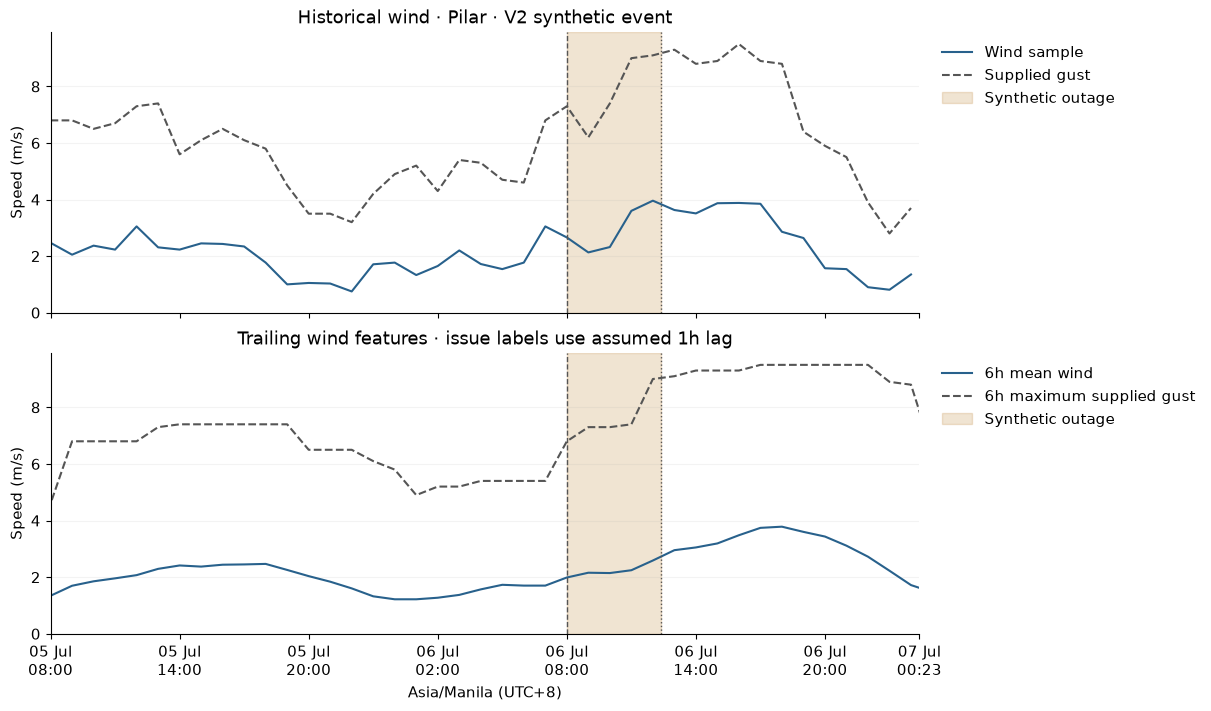

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
axes[0].plot(visible_labels.index, visible_labels.wind_speed_10m_m_s, color=BLUE, label="Wind sample")
axes[0].plot(visible_labels.index, visible_labels.wind_gusts_10m_m_s, color=GREY, linestyle="--", label="Supplied gust")
axes[0].set(title=f"Historical wind · {weather_municipality} · V2 synthetic event", ylabel="Speed (m/s)")
axes[1].plot(weather_features.index, weather_features.wind_mean_6h_m_s, color=BLUE, label="6h mean wind")
axes[1].plot(weather_features.index, weather_features.gust_max_6h_m_s, color=GREY, linestyle="--", label="6h maximum supplied gust")
axes[1].set(title="Trailing wind features · issue labels use assumed 1h lag", ylabel="Speed (m/s)", xlabel="Asia/Manila (UTC+8)")
for axis in axes:
    mark_outage(axis)
    axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

In [16]:
largest_rain_label = visible_labels.precipitation_mm.idxmax()
largest_gust_label = visible_labels.wind_gusts_10m_m_s.idxmax()
display(Markdown(f"**Timeline findings:** the largest displayed hourly rain amount is "
    f"{visible_labels.precipitation_mm.max():.2f} mm, labeled {largest_rain_label:%d %b %H:%M}. "
    f"The largest displayed supplied gust is {visible_labels.wind_gusts_10m_m_s.max():.2f} m/s "
    f"at {largest_gust_label:%d %b %H:%M}. These hourly-label summaries exclude the extra final support label; "
    "neither a peak nor its timing proves why the V2 synthetic event occurred."))

**Timeline findings:** the largest displayed hourly rain amount is 10.70 mm, labeled 05 Jul 11:00. The largest displayed supplied gust is 9.50 m/s at 06 Jul 16:00. These hourly-label summaries exclude the extra final support label; neither a peak nor its timing proves why the V2 synthetic event occurred.

### Municipal conditions during the outage

Temperature, relative humidity, surface pressure and two modeled soil-moisture depths describe the local environmental context. Their samples inside `[onset, restoration)` are summarized without weighting a full hourly record by the fractional restoration time.

| Variable | Units | Interpretation |
|---|---|---|
| Temperature / relative humidity | °C / % | Air temperature and humidity relative to saturation |
| Surface pressure | hPa | Pressure at the representative weather point, not sea-level pressure |
| Soil moisture, 0–7 / 7–28 cm | m³/m³ | Modeled volumetric water content; not a measurement of saturated ground or a failure mechanism |

In [17]:
context_labels = {
    "temperature_2m_c": "Temperature (°C)",
    "relative_humidity_2m_pct": "Relative humidity (%)",
    "surface_pressure_hpa": "Surface pressure (hPa)",
    "soil_moisture_0_to_7cm_m3_m3": "Soil moisture 0–7 cm (m³/m³)",
    "soil_moisture_7_to_28cm_m3_m3": "Soil moisture 7–28 cm (m³/m³)",
}
municipal_context = visible_labels[list(context_labels)]
during_municipal = municipal_context.loc[(municipal_context.index >= onset)
    & (municipal_context.index < restoration)]
display(during_municipal.rename(columns=context_labels).round(3))

,Temperature (°C),Relative humidity (%),Surface pressure (hPa),Soil moisture 0–7 cm (m³/m³),Soil moisture 7–28 cm (m³/m³)
valid_time,,,,,
2025-07-06 08:00:00+08:00,26.5,93,1008.5,0.505,0.491
2025-07-06 09:00:00+08:00,27.2,88,1009.9,0.510,0.493
2025-07-06 10:00:00+08:00,27.5,90,1010.3,0.508,0.494
2025-07-06 11:00:00+08:00,26.9,88,1009.8,0.506,0.494
2025-07-06 12:00:00+08:00,28.4,81,1008.8,0.503,0.494


### ERA5 atmospheric context

ERA5 uses a separate coarse grid. The grid coordinates recorded by the V2 event are checked against the NetCDF coordinates; UTC valid times are converted to Manila. Source nulls remain missing rather than being interpreted as clear skies or zero inhibition.

| Variable | Units | Interpretation |
|---|---|---|
| CAPE / CIN | J/kg | Convective available potential energy / the energy barrier to convection |
| Total column water vapour | kg/m² | Atmospheric-column water vapour, not precipitation |
| Cloud-base height | m | Modeled cloud-base height above the surface |

CAPE alone does not establish a thunderstorm or lightning strike. CIN retains its supplied sign. No severe-weather threshold or causal classification is inferred from these variables.

In [18]:
era5_variables = ["cape", "cin", "tcwv", "cbh"]
expected_era5_units = {"cape": "J kg**-1", "cin": "J kg**-1", "tcwv": "kg m**-2", "cbh": "m"}
grid_latitude, grid_longitude = float(event.era5_latitude), float(event.era5_longitude)
utc_start = read_start.tz_convert("UTC").tz_localize(None).to_datetime64()
utc_end = read_end.tz_convert("UTC").tz_localize(None).to_datetime64()
with xr.open_dataset(sources["era5"], engine="h5netcdf") as era5:
    assert era5.attrs.get("Conventions") == "CF-1.7"
    assert era5.valid_time.encoding.get("units") == "seconds since 1970-01-01"
    assert grid_latitude in era5.latitude.values and grid_longitude in era5.longitude.values
    for name, unit in expected_era5_units.items():
        assert era5[name].attrs.get("units") == unit, f"Review changed units for {name}."
    all_era5_times = pd.DatetimeIndex(era5.valid_time.values).tz_localize("UTC").tz_convert(MANILA)
    era5_source_coverage = pd.DataFrame([{"Variable": name,
        "First local hour": str(all_era5_times.min()), "Last local hour": str(all_era5_times.max()),
        "Time steps": len(all_era5_times), "Grid cells": int(era5.sizes["latitude"] * era5.sizes["longitude"]),
        "Source missing (%)": 100 * int(era5[name].isnull().sum()) / era5[name].size,
        "Units": era5[name].attrs["units"]} for name in era5_variables])
    grid_slice = era5[era5_variables].sel(latitude=grid_latitude, longitude=grid_longitude)
    era5_slice = grid_slice.sel(valid_time=slice(utc_start, utc_end)).load()
print(f"Recorded event grid: {grid_latitude:.2f}°N, {grid_longitude:.2f}°E; 0.25° spacing")
display(era5_source_coverage.round({"Source missing (%)": 3}))

Recorded event grid: 14.75°N, 120.50°E; 0.25° spacing


,Variable,First local hour,Last local hour,Time steps,Grid cells,Source missing (%),Units
0,cape,2019-01-01 08:00:00+08:00,2026-07-01 07:00:00+08:00,65712,12,0.000,J kg**-1
1,cin,2019-01-01 08:00:00+08:00,2026-07-01 07:00:00+08:00,65712,12,35.195,J kg**-1
2,tcwv,2019-01-01 08:00:00+08:00,2026-07-01 07:00:00+08:00,65712,12,0.000,kg m**-2
3,cbh,2019-01-01 08:00:00+08:00,2026-07-01 07:00:00+08:00,65712,12,5.043,m


In [19]:
era5_times = pd.DatetimeIndex(era5_slice.valid_time.values).tz_localize("UTC").tz_convert(MANILA)
assert era5_times.is_unique and era5_times.is_monotonic_increasing
era5_missing_hours = expected_hours.difference(era5_times)
era5_hourly = pd.DataFrame({name: era5_slice[name].values for name in era5_variables}, index=era5_times)
assert not np.isinf(era5_hourly.to_numpy(dtype=float)).any(), "Review infinite source values."
era5_hourly = era5_hourly.reindex(expected_hours)
era5_hourly.index.name = "valid_time"
era5_missing_values = era5_hourly.isna().sum()
display(era5_missing_values.to_frame("Missing values in loaded grid window"))
assert len(era5_missing_hours) == 0, "Review missing ERA5 timestamps."
# Preserve any source nulls; they must remain gaps, not invented clear skies or zero inhibition.
for name in ["cape", "tcwv", "cbh"]:
    assert era5_hourly[name].dropna().ge(0).all()
assert np.isclose(era5_hourly.loc[onset, "cape"], float(event.cape_j_kg), rtol=1e-6)

,Missing values in loaded grid window
cape,0
cin,2
tcwv,0
cbh,0


### Before, during and after comparison

Hourly sample means and ranges are reported with their sample counts. Period lengths differ, and these summaries are neither time-weighted means nor independent-sample significance tests. Missing ERA5 values reduce valid counts and are not imputed. Municipal and ERA5 measurements remain distinct sources with different spatial support.

In [20]:
era5_labels = {"cape": "CAPE (J/kg)", "cin": "CIN (J/kg)",
    "tcwv": "Column water vapour (kg/m²)", "cbh": "Cloud-base height (m)"}
context_values = municipal_context.rename(columns=context_labels).join(
    era5_hourly.loc[timeline_start:timeline_end].rename(columns=era5_labels), validate="one_to_one")
phase_masks = {
    "Before": context_values.index < onset,
    "During": (context_values.index >= onset) & (context_values.index < restoration),
    "After": context_values.index >= restoration,
}
phase_samples = pd.Series({name: int(mask.sum()) for name, mask in phase_masks.items()}, name="Expected hourly samples")
assert phase_samples.sum() == len(context_values)
display(phase_samples.to_frame())

,Expected hourly samples
Before,24
During,5
After,12


In [21]:
context_summary = pd.DataFrame({name + " mean": context_values.loc[mask].mean()
    for name, mask in phase_masks.items()})
during_context = context_values.loc[phase_masks["During"]]
context_summary["During min"] = during_context.min()
context_summary["During max"] = during_context.max()
context_summary["Valid during / expected"] = during_context.count().astype(str) + " / " + str(phase_samples["During"])
display(context_summary.round(3))
print("Expected before/during/after samples:", phase_samples.tolist())

,Before mean,During mean,After mean,During min,During max,Valid during / expected
Temperature (°C),25.904,27.300,26.567,26.500,28.400,5 / 5
Relative humidity (%),94.208,88.000,90.083,81.000,93.000,5 / 5
Surface pressure (hPa),1007.879,1009.460,1009.100,1008.500,1010.300,5 / 5
Soil moisture 0–7 cm (m³/m³),0.505,0.506,0.496,0.503,0.510,5 / 5
Soil moisture 7–28 cm (m³/m³),0.498,0.493,0.492,0.491,0.494,5 / 5
CAPE (J/kg),649.120,760.450,567.323,562.250,1177.750,5 / 5
CIN (J/kg),39.932,44.966,73.711,9.109,86.297,5 / 5
Column water vapour (kg/m²),60.088,61.026,58.540,60.413,61.485,5 / 5
Cloud-base height (m),211.258,273.506,205.142,132.459,331.467,5 / 5


Expected before/during/after samples: [24, 5, 12]


### Environmental trajectories

The municipal and ERA5 panels retain native units. Focused vertical scales show changes within each variable; panel heights are not comparable across variables. Gaps indicate missing source values. The common outage shading provides temporal context without assigning a mechanism to the simulated event.

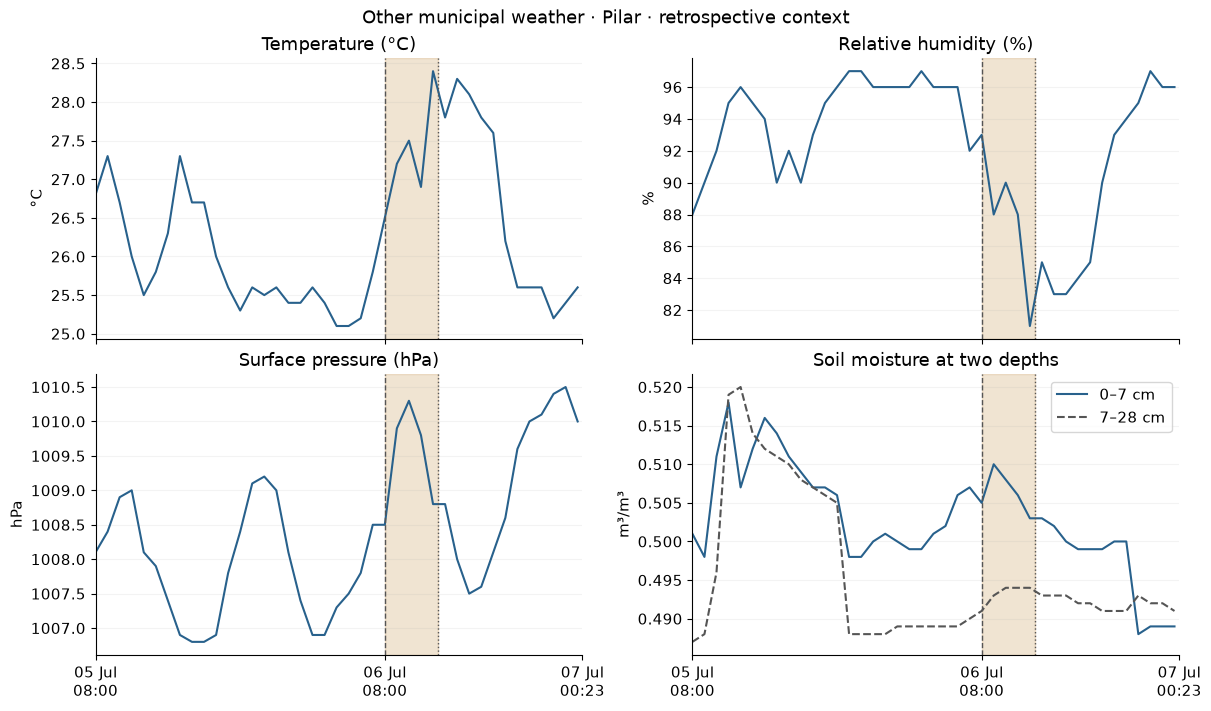

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for axis, column in zip(axes.flat, list(context_labels)[:3]):
    axis.plot(municipal_context.index, municipal_context[column], color=BLUE)
    axis.set(title=context_labels[column], ylabel=context_labels[column].split("(")[-1].rstrip(")"))
soil_axis = axes.flat[3]
for column, label, style, color in [
    ("soil_moisture_0_to_7cm_m3_m3", "0–7 cm", "-", BLUE),
    ("soil_moisture_7_to_28cm_m3_m3", "7–28 cm", "--", GREY)]:
    soil_axis.plot(municipal_context.index, municipal_context[column], label=label, linestyle=style, color=color)
soil_axis.set(title="Soil moisture at two depths", ylabel="m³/m³")
soil_axis.legend(loc="best")
for axis in axes.flat:
    mark_outage(axis)
    axis.set_autoscaley_on(True)
    axis.relim()
    axis.autoscale_view(scalex=False, scaley=True)
    axis.set_xticks([timeline_start, onset, timeline_end])
fig.suptitle(f"Other municipal weather · {weather_municipality} · retrospective context")
plt.show()

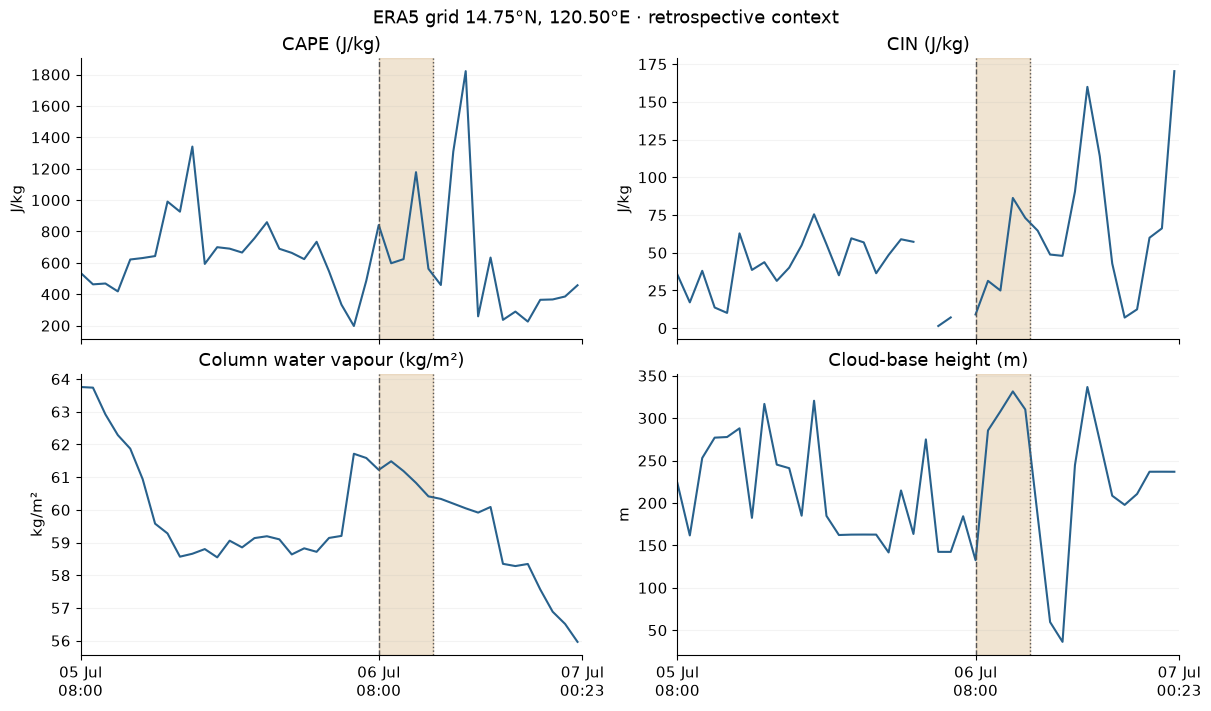

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
era5_visible = era5_hourly.loc[timeline_start:timeline_end]
for axis, column in zip(axes.flat, era5_variables):
    axis.plot(era5_visible.index, era5_visible[column], color=BLUE)
    axis.set(title=era5_labels[column], ylabel=era5_labels[column].split("(")[-1].rstrip(")"))
    mark_outage(axis)
    axis.set_autoscaley_on(True)
    axis.relim()
    axis.autoscale_view(scalex=False, scaley=True)
    axis.set_xticks([timeline_start, onset, timeline_end])
fig.suptitle(f"ERA5 grid {grid_latitude:.2f}°N, {grid_longitude:.2f}°E · retrospective context")
plt.show()

In [24]:
display(Markdown(f"**During the selected outage:** temperature ranges from "
    f"{during_municipal.temperature_2m_c.min():.1f} to {during_municipal.temperature_2m_c.max():.1f} °C; "
    f"humidity from {during_municipal.relative_humidity_2m_pct.min():.0f} to "
    f"{during_municipal.relative_humidity_2m_pct.max():.0f}%. "
    f"CAPE ranges from {during_context['CAPE (J/kg)'].min():.1f} to "
    f"{during_context['CAPE (J/kg)'].max():.1f} J/kg across {phase_samples['During']} hourly labels. "
    "These are overlapping conditions; they do not identify an outage mechanism."))

**During the selected outage:** temperature ranges from 26.5 to 28.4 °C; humidity from 81 to 93%. CAPE ranges from 562.2 to 1177.8 J/kg across 5 hourly labels. These are overlapping conditions; they do not identify an outage mechanism.

### Shared-weather exposure

Concurrent events in the same municipality reuse the same representative weather series. Their count quantifies overlap in the V2 simulation; it does not create independent weather evidence or establish a common real-world cause.

In [25]:
all_onsets = pd.to_datetime(events.start_time, format="mixed", utc=True).dt.tz_convert(MANILA)
all_restorations = pd.to_datetime(events.end_time, format="mixed", utc=True).dt.tz_convert(MANILA)
overlap_mask = events.municipality_psgc.eq(event.municipality_psgc) & (all_onsets < restoration) & (all_restorations > onset)
other_overlapping_events = events.loc[overlap_mask & events.outage_id.ne(selected_outage_id)]
print("Other overlapping V2 synthetic events in the same municipality:", len(other_overlapping_events))
display(other_overlapping_events[["outage_id", "barangay", "start_time", "end_time"]].head(5))
print("No causal comparison or independent-sample test is performed.")

Other overlapping V2 synthetic events in the same municipality: 0


,outage_id,barangay,start_time,end_time


No causal comparison or independent-sample test is performed.


## 8. Predictive-use limitations and leakage controls

| Analytical use | Time rule | Interpretation |
|---|---|---|
| Retrospective event timeline | Before, during and after onset | Environmental context only |
| V2 pre-event snapshot | Prediction at `onset−1h`; observations end at `onset−2h` | Valid-time ordering checked; actual release availability unverified |
| Operational prediction | Verified availability at the prediction cutoff and an appropriate archived forecast vintage | Not established by these historical files |

Restoration, generated cause and future realized weather are excluded from the pre-event diagnostics. Recomputing from the truncated past-only source verifies that later observations do not affect the snapshot. Historical reanalysis can arrive or be revised after valid time; the additional one-hour lag does not remove that deployment limitation.

In [26]:
past_only = weather_hourly.loc[:cutoff]
assert past_only.index.max() < issue_time
past_checks = pd.Series({
    "rain_sum_6h_mm": past_only.precipitation_mm.rolling("6h", closed="right", min_periods=6).sum().loc[cutoff],
    "rain_sum_24h_mm": past_only.precipitation_mm.rolling("24h", closed="right", min_periods=24).sum().loc[cutoff],
    "wind_mean_6h_m_s": past_only.wind_speed_10m_m_s.rolling("6h", closed="right", min_periods=6).mean().loc[cutoff],
    "gust_max_6h_m_s": past_only.wind_gusts_10m_m_s.rolling("6h", closed="right", min_periods=6).max().loc[cutoff],
})
assert np.allclose(past_checks, pre_event_features, rtol=0, atol=1e-10)
assert six_labels.max() == cutoff and twenty_four_labels.max() == cutoff
assert len(six_labels) == 6 and len(twenty_four_labels) == 24
assert {name: fingerprint(path) for name, path in sources.items()} == source_hashes_before
print("Checks passed: one location, complete hours, matching independent calculations, past-only inputs, unchanged sources.")

Checks passed: one location, complete hours, matching independent calculations, past-only inputs, unchanged sources.


## 9. Findings, limitations and conclusions

The event population and checksum checks establish that this report uses V2 rather than V1 labels. Full-source coverage is separated from selected-window integrity, and weather shared across municipalities or barangays is not treated as independent station evidence.

The selected case has sufficient hourly support for before/during/after comparisons. Its generated Weather / Storm category is a simulation attribute. Temporal coincidence with precipitation, wind, moisture or atmospheric instability cannot verify a real outage mechanism.

The pre-event snapshot follows the V2 one-hour-forward target clock, while the timeline deliberately retains later observations for retrospective reporting. The diagnostic windows here are not a substitute for the separate V2 predictor manifest, forecast-availability audit or model evaluation. No model, API or forecasting claim is produced.

In [27]:
before_mean = context_summary.loc["Relative humidity (%)", "Before mean"]
during_mean = context_summary.loc["Relative humidity (%)", "During mean"]
display(Markdown(
    f"**Calculated findings:** the selected V2 event lasts {event.duration_minutes:.2f} minutes. "
    f"The comparison contains {phase_samples['Before']} before, {phase_samples['During']} during and "
    f"{phase_samples['After']} after hourly labels. Mean humidity is {before_mean:.2f}% before and "
    f"{during_mean:.2f}% during the event; the change is {during_mean-before_mean:+.2f} percentage points. "
    f"The visible window's largest hourly precipitation amount is {visible_labels.precipitation_mm.max():.2f} mm "
    f"and largest supplied gust is {visible_labels.wind_gusts_10m_m_s.max():.2f} m/s. "
    f"There are {len(other_overlapping_events)} other overlapping V2 events in this municipality. "
    "These findings describe the selected simulated event and its shared retrospective weather context."))
assert {name: fingerprint(path) for name, path in sources.items()} == source_hashes_before

**Calculated findings:** the selected V2 event lasts 263.26 minutes. The comparison contains 24 before, 5 during and 12 after hourly labels. Mean humidity is 94.21% before and 88.00% during the event; the change is -6.21 percentage points. The visible window's largest hourly precipitation amount is 10.70 mm and largest supplied gust is 9.50 m/s. There are 0 other overlapping V2 events in this municipality. These findings describe the selected simulated event and its shared retrospective weather context.